In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("13 buyscom.csv")

In [3]:
df.head()

,Age,Income,Student,Creditrating,Buyscomputer
0,Youth,High,No,Fair,No
1,Youth,High,No,Excellent,No
2,Middle,High,No,Fair,Yes
3,Senior,Medium,No,Fair,Yes
4,Senior,Low,Yes,Fair,Yes


In [4]:
df.shape

(14, 5)

In [5]:
df.size

70

# Steps we're going to perform

1) Preprocess + EDA + Feature selection.
2) Extract input and output columns.
3) Scale the values.
4) Train/test split.
5) Train the model.
6) Evaluate the models/ Selecting the model
7) Deploy the model.

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Age           14 non-null     object
 1   Income        14 non-null     object
 2   Student       14 non-null     object
 3   Creditrating  14 non-null     object
 4   Buyscomputer  14 non-null     object
dtypes: object(5)
memory usage: 692.0+ bytes


# Let's  first perform Label Encoding

In [7]:
from sklearn.preprocessing import LabelEncoder

In [8]:
le = LabelEncoder()

In [9]:
cols_to_encode = ['Age', "Income", "Student", "Creditrating", "Buyscomputer"]

In [10]:
df[cols_to_encode] = df[cols_to_encode].apply(le.fit_transform)

In [11]:
df.head()

,Age,Income,Student,Creditrating,Buyscomputer
0,2,0,0,1,0
1,2,0,0,0,0
2,0,0,0,1,1
3,1,2,0,1,1
4,1,1,1,1,1


# Let's now seperate predictor and class variables.

Here we'll take only two columns as predictor variables so that we can understand properly.

In [12]:
x = df.iloc[:,0:2]

In [13]:
x.head()

,Age,Income
0,2,0
1,2,0
2,0,0
3,1,2
4,1,1


In [14]:
y = df['Buyscomputer']

In [15]:
y.head()

0    0
1    0
2    1
3    1
4    1
Name: Buyscomputer, dtype: int32

In [16]:
print(x.shape)
print(y.shape)

(14, 2)
(14,)


# Performing train/test split.

In [17]:
from sklearn.model_selection import train_test_split

In [18]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2)

In [19]:
print(x_train)
print()
print()
print()
print(x_test)


# test_size = 0.2 means 20% in test set and 80% in train set.
# We can se that 80% of 14 i.e 11 is in train set and 3 is in test set.

# Here, we can see row number as well from index. But after scaling, we won't be able to identify the row number as scaling will
# convert the data into an array.

    Age  Income
4     1       1
1     2       0
12    0       0
8     2       1
3     1       2
10    2       2
6     1       1
0     2       0
7     2       2
9     1       2
13    1       2



    Age  Income
2     0       0
5     0       1
11    0       2


# Scaling the values between -1 and 1(Applying Standard scaler)

In [20]:
from sklearn.preprocessing import StandardScaler

In [21]:
ss = StandardScaler()

In [22]:
x_train = ss.fit_transform(x_train)
print(x_train)

# See, as said above, we can't identify the row bcz we are not given any index number here

[[-0.56568542 -0.21821789]
 [ 0.98994949 -1.41841629]
 [-2.12132034 -1.41841629]
 [ 0.98994949 -0.21821789]
 [-0.56568542  0.98198051]
 [ 0.98994949  0.98198051]
 [-0.56568542 -0.21821789]
 [ 0.98994949 -1.41841629]
 [ 0.98994949  0.98198051]
 [-0.56568542  0.98198051]
 [-0.56568542  0.98198051]]


In [23]:
x_test = ss.fit_transform(x_test)

In [24]:
x_test

array([[ 0.        , -1.22474487],
       [ 0.        ,  0.        ],
       [ 0.        ,  1.22474487]])

# Why do we not scale class variables(Buys computer here)?

* Note: We don't scale the class variables i.e **y_train** and **y_test** bcz it is the output in the form of 0 and 1.
* 0 means NO and 1 means Yes. If we scale these values, Standard Scaler will scale them between -1 and 1.
* Then after scaling we would get the numbers as 0.0005, -0.001, 0.012451, and so on.
* How can we know if it is indicating 'Yes' or 'No'? Hence class variables are not to be scaled

# Training the model.

We will use Logistic regression model.

In [25]:
from sklearn.linear_model import LogisticRegression

In [26]:
le = LogisticRegression()

In [27]:
le.fit(x_train, y_train)

LogisticRegression()

# Evaluation of the model.

In [28]:
# Before evaluation, we'll have to predict on x_test. Bcz whithour prediction on testing data, how can we evaluate the
# model like what is the accuracy or how well is it performing.

In [30]:
y_pred = le.predict(x_test) 

In [34]:
print(y_pred)
print()
print()
print()

print(y_test)

# We can see, prediction is [Yes, 'Yes' and Yes] wheres real values on y_test were [Yes, No, Yes] so on evaluation, we will get
# accuracy between 0.6 and 0.67.

[1 1 1]



2     1
5     0
11    1
Name: Buyscomputer, dtype: int32


In [35]:
# Let's see if we're getting accuracy which we calculated manually or not.

from sklearn.metrics import accuracy_score

In [36]:
accuracy = accuracy_score(y_test, y_pred)
print(accuracy)

# See, we are getting the same accuracy as we predicted.

0.6666666666666666


# Plotting the decision boundry.

We know that machine learning model plots a decision boundry and classifies the data points on left, right or 
on that boundry line and makes prediction accordingly.

Let's see how has this Linear regression model formed a decision boundry.

To plot it, class **plot_decision_regions** under **mlxtend** module is used.

In [37]:
from mlxtend.plotting import plot_decision_regions

<AxesSubplot: >

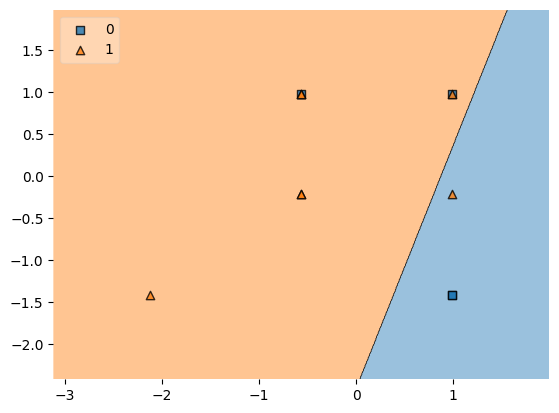

In [57]:
plot_decision_regions(X = x_train, y = y_train.values, clf = le, legend = 2)

# Parameter 'X' takes x data in the form of an array. But as we have scaled our x_train, it automatically converted into an numpy array.
# Same goes with 'y'. But as it is not scaled, it is not in an array form. So by using 'y_train.values' we will convert it into an array.
# 'clf' takes the model.

# We give x_train and y_train here bcz our model is trained on them. So we can find decision boundry condsidering them only.